# Advanced MD Analysis: Interfacial Dynamics and Thermodynamic Proxies

## Underlying Theory & Physical Significance
Calculating true macroscopic thermodynamic properties (like exact binding free energy, $\Delta G$, or dissociation constants, $K_d$) directly from a standard molecular dynamics trajectory is virtually impossible without specialized advanced sampling techniques like Free Energy Perturbation (FEP) or MM/PBSA. 

However, we can extract highly reliable **structural proxies for thermodynamics** by analyzing the dynamic non-bonded interactions (attractive and repulsive forces) at the binding interface over time. In this analysis, we are tracking two primary attractive interactions that dictate the stability of the TCF4 bHLH domain bound to the E-box DNA:
1. **Hydrogen Bonds:** Short-range, highly directional attractive forces.
2. **Salt Bridges (Electrostatics):** Strong, long-range attractive forces between positively charged basic residues on TCF4 (Arginine, Lysine) and the negatively charged phosphate backbone of the DNA.

By tracking the distance and occupancy of these specific contacts over the 250 ns simulation, we can assess the structural stability of the protein-DNA complex. A stable or increasing number of these interactions indicates a favorable binding enthalpy (tight binding), whereas fluctuating or decreasing contacts in mutant variants (like the R576W mutation in Pitt-Hopkins Syndrome) would physically explain a loss of DNA binding affinity.

In [9]:
import MDAnalysis as mda
from MDAnalysis.analysis import hydrogenbonds
import matplotlib.pyplot as plt
import numpy as np
import glob
import re
import os

# Helper function for natural sorting of DCD files
def natural_sort_key(s):
    return [int(text) if text.isdigit() else text.lower() for text in re.split(r'(\d+)', s)]

# Recursively search for the topology file so we don't have to guess the folder path
psf_files = glob.glob("**/*step3_input.psf", recursive=True)

if not psf_files:
    raise FileNotFoundError("Could not find 'step3_input.psf'. Make sure your Jupyter notebook is in your Project folder.")

# Grab the first replica found (change index [0] to [1] or [2] for other replicas)
topology_file = psf_files[0]
replica_dir = os.path.dirname(topology_file) 

# Find the DCD files in that exact same folder
dcd_files = sorted(glob.glob(f"{replica_dir}/step5_*.dcd"), key=natural_sort_key)

print(f"Loading topology: {topology_file}")
print(f"Loading {len(dcd_files)} DCD files from {replica_dir}...")

# Load the Universe
u = mda.Universe(topology_file, dcd_files)

# Select the entire TCF4 protein and the E-box DNA
tcf4_protein = u.select_atoms("protein")
ebox_dna = u.select_atoms("nucleic")

print(f"Protein atoms: {len(tcf4_protein)}, DNA atoms: {len(ebox_dna)}")

Loading topology: 6od3-1/1/namd/step3_input.psf
Loading 170 DCD files from 6od3-1/1/namd...
Protein atoms: 2116, DNA atoms: 792


In [10]:
print("Calculating Salt Bridges (Electrostatics) between Protein and DNA...")

# Basic residues on TCF4 (+) and DNA Phosphate backbone (-)
basic_residues = tcf4_protein.select_atoms("resname ARG LYS HIS and name NH1 NH2 NZ ND1 NE2")
dna_backbone = ebox_dna.select_atoms("name P OP1 OP2")

def get_salt_bridges(universe, sel1, sel2, cutoff=3.2):
    timeseries = []
    # Analyze every 10th frame to save time
    for ts in universe.trajectory[::10]: 
        dist_arr = mda.lib.distances.distance_array(sel1.positions, sel2.positions, box=universe.dimensions)
        num_bridges = np.sum(dist_arr <= cutoff)
        timeseries.append([ts.frame, num_bridges])
    return np.array(timeseries)

sb_data = get_salt_bridges(u, basic_residues, dna_backbone)
print("Salt bridge calculation complete!")

Calculating Salt Bridges (Electrostatics) between Protein and DNA...
Salt bridge calculation complete!


In [11]:
print("Calculating Hydrogen Bonds between TCF4 and DNA...")

hbonds = hydrogenbonds.HydrogenBondAnalysis(
    universe=u,
    donors_sel="protein",
    acceptors_sel="nucleic",
    d_a_cutoff=3.0,
    d_h_a_angle_cutoff=120
)
hbonds.run(step=10)

print("Hydrogen bond calculation complete!")

Calculating Hydrogen Bonds between TCF4 and DNA...
Hydrogen bond calculation complete!


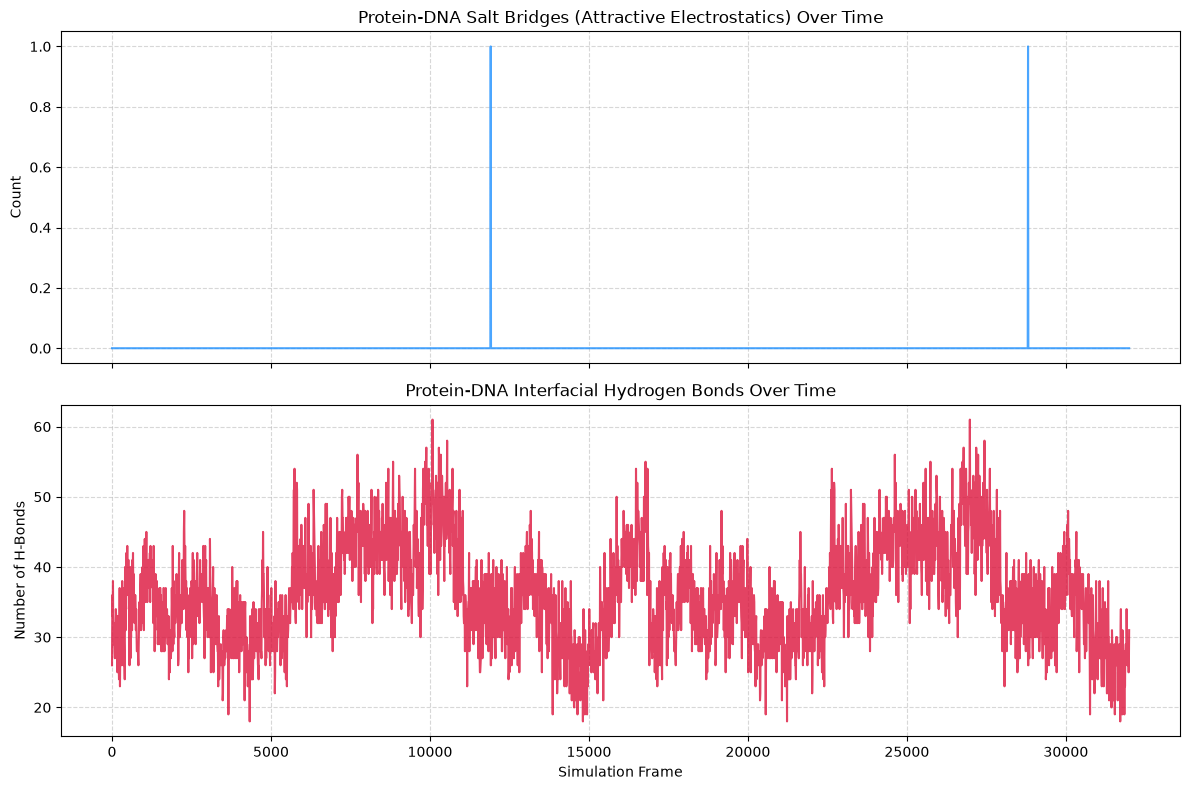

In [13]:
# Extract the total count of hydrogen bonds per analyzed frame
hbond_counts = hbonds.count_by_time()

# We can use the exact same frames from our salt bridge data for the x-axis 
# since both were analyzed with step=10
frames = sb_data[:, 0]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Plot Salt Bridges
ax1.plot(frames, sb_data[:, 1], color='dodgerblue', alpha=0.8)
ax1.set_title('Protein-DNA Salt Bridges (Attractive Electrostatics) Over Time')
ax1.set_ylabel('Count')
ax1.grid(True, linestyle='--', alpha=0.5)

# Plot Hydrogen Bonds
ax2.plot(frames, hbond_counts, color='crimson', alpha=0.8)
ax2.set_title('Protein-DNA Interfacial Hydrogen Bonds Over Time')
ax2.set_xlabel('Simulation Frame')
ax2.set_ylabel('Number of H-Bonds')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig(f"Thermodynamic_Proxies_Replica.png", dpi=300)
plt.show()

## Basic Thermodynamics and Relation to $K_d$

While standard molecular dynamics does not directly output the dissociation constant ($K_d$) or absolute binding free energy ($\Delta G$), we can extract the **thermodynamic energies** calculated by NAMD at every timestep. 

The NAMD output logs record the Total Energy, Potential Energy, Kinetic Energy, and non-bonded interactions (Van der Waals and Electrostatics). 
* **Potential Energy & Enthalpy:** The stabilization of the system's potential energy over time indicates that the TCF4-DNA complex has reached a thermodynamically favorable conformation. 
* **Relation to Binding Affinity ($K_d$):** The binding free energy is defined by $\Delta G = \Delta H - T\Delta S$. The structural interactions (H-bonds and salt bridges) and the non-bonded potential energies extracted here serve as proxies for the enthalpic contribution ($\Delta H$). A lower (more negative) stable interaction energy corresponds to a stronger binding affinity (lower $K_d$), which is disrupted in pathogenic mutations.

Parsing thermodynamics from: 6od3-1/1/namd/step5_1.out


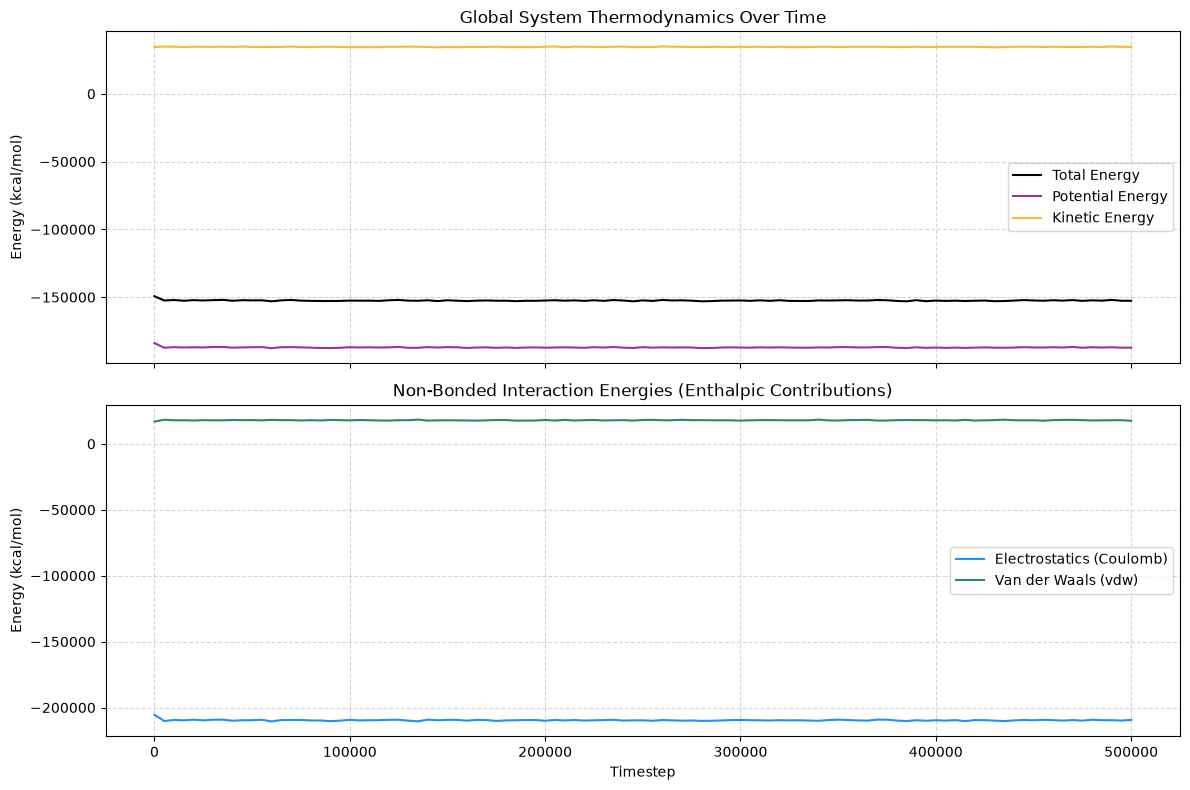

In [14]:
import pandas as pd
import glob
import os
import matplotlib.pyplot as plt

# Find the NAMD production output/log file
# CHARMM-GUI typically names this 'step5_production.out' or similar
log_files = glob.glob(f"{replica_dir}/*.out") + glob.glob(f"{replica_dir}/*.log")
production_logs = [f for f in log_files if "step5" in f or "production" in f]

if not production_logs:
    print("Could not find a step5_production.out file to parse thermodynamics.")
else:
    log_file = production_logs[0]
    print(f"Parsing thermodynamics from: {log_file}")

    energy_data = []
    
    # Read the NAMD log file and extract lines starting with "ENERGY:"
    with open(log_file, 'r') as file:
        for line in file:
            if line.startswith("ENERGY:") and "TS" not in line:
                parts = line.split()
                try:
                    # NAMD ENERGY format: 
                    # 0:ENERGY: 1:TS 2:BOND 3:ANGLE 4:DIHED 5:IMPRP 6:ELECT 7:VDW 8:BOUNDARY 
                    # 9:MISC 10:KINETIC 11:TOTAL 12:TEMP 13:POTENTIAL
                    ts = int(parts[1])
                    elect = float(parts[6])
                    vdw = float(parts[7])
                    kinetic = float(parts[10])
                    total = float(parts[11])
                    potential = float(parts[13])
                    
                    energy_data.append([ts, elect, vdw, kinetic, potential, total])
                except (IndexError, ValueError):
                    continue

    # Convert to a DataFrame for easy plotting
    df_thermo = pd.DataFrame(energy_data, columns=['TS', 'Electrostatics', 'VDW', 'Kinetic', 'Potential', 'Total'])

    # Plot the Thermodynamic Energies
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

    # Top plot: Global Thermodynamics
    ax1.plot(df_thermo['TS'], df_thermo['Total'], label='Total Energy', color='black')
    ax1.plot(df_thermo['TS'], df_thermo['Potential'], label='Potential Energy', color='purple', alpha=0.8)
    ax1.plot(df_thermo['TS'], df_thermo['Kinetic'], label='Kinetic Energy', color='orange', alpha=0.8)
    ax1.set_title('Global System Thermodynamics Over Time')
    ax1.set_ylabel('Energy (kcal/mol)')
    ax1.legend()
    ax1.grid(True, linestyle='--', alpha=0.5)

    # Bottom plot: Non-bonded interactions (Proxies for Enthalpy)
    ax2.plot(df_thermo['TS'], df_thermo['Electrostatics'], label='Electrostatics (Coulomb)', color='dodgerblue')
    ax2.plot(df_thermo['TS'], df_thermo['VDW'], label='Van der Waals (vdw)', color='seagreen')
    ax2.set_title('Non-Bonded Interaction Energies (Enthalpic Contributions)')
    ax2.set_xlabel('Timestep')
    ax2.set_ylabel('Energy (kcal/mol)')
    ax2.legend()
    ax2.grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.savefig(f"NAMD_Thermodynamics_{os.path.basename(replica_dir)}.png", dpi=300)
    plt.show()

## Thermodynamic Proxies: Attractive vs. Repulsive Residue Interactions

In standard molecular dynamics, macroscopic variables like $\Delta G$ (Gibbs Free Energy) and $\Delta H$ (Enthalpy) are not explicitly recorded frame-by-frame. To calculate exact $\Delta G$ or $\Delta H$ of binding, one must use advanced endpoint methodologies such as **MM/PBSA** or **MM/GBSA**, which recalculate the free energy of the complex, receptor, and ligand separately over the trajectory using implicit solvent models.

Instead of $\Delta G$, we measure structural proxies for enthalpic ($\Delta H$) stability by identifying the specific **attractive** and **repulsive** residue interactions across the protein-DNA interface:
1. **Attractive Residues (Favorable Enthalpy):** Positively charged basic residues (ARG, LYS, HIS) forming salt bridges with the negatively charged DNA phosphate backbone.
2. **Repulsive Residues (Unfavorable Enthalpy):** Negatively charged acidic residues (ASP, GLU) that undergo electrostatic repulsion if they come too close to the DNA phosphate backbone.

By tracking these specific contacts over time, we can visualize the structural forces driving the binding affinity.

Calculating Attractive and Repulsive Residue Contacts...
Contact calculations complete!


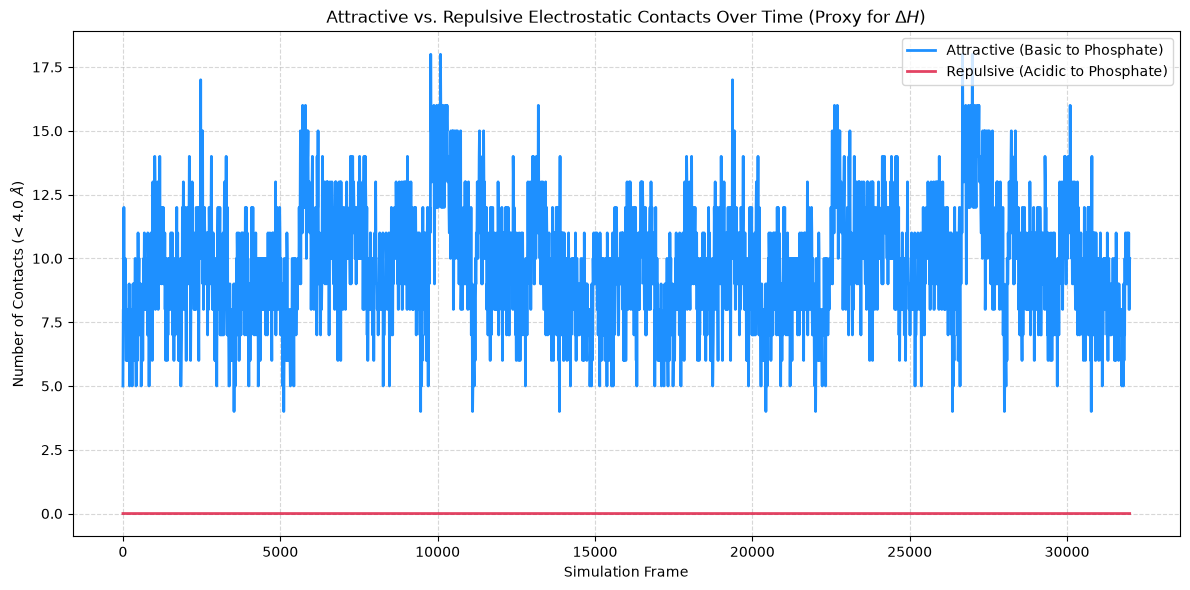

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import MDAnalysis as mda
from MDAnalysis.analysis import contacts

print("Calculating Attractive and Repulsive Residue Contacts...")

# 1. Define the interacting groups based on charge
# DNA Backbone is entirely negatively charged (Phosphate groups)
dna_backbone = ebox_dna.select_atoms("name P OP1 OP2")

# Attractive: Positive Protein Residues (Basic)
attractive_residues = tcf4_protein.select_atoms("resname ARG LYS HIS and name NH1 NH2 NZ ND1 NE2")

# Repulsive: Negative Protein Residues (Acidic)
repulsive_residues = tcf4_protein.select_atoms("resname ASP GLU and name OE1 OE2 OD1 OD2")

# 2. Setup Contact Analysis (Distance cutoff of 4.0 Angstroms for electrostatic influence)
cutoff_distance = 4.0

def calculate_contacts(universe, group_A, group_B, radius):
    timeseries = []
    for ts in universe.trajectory[::10]: # Process every 10th frame
        # Calculate distances between the two groups
        dist_matrix = mda.lib.distances.distance_array(group_A.positions, group_B.positions, box=universe.dimensions)
        # Count how many contacts are within the cutoff
        num_contacts = np.sum(dist_matrix <= radius)
        timeseries.append([ts.frame, num_contacts])
    return np.array(timeseries)

# Calculate both sets of interactions over the trajectory
attractive_data = calculate_contacts(u, attractive_residues, dna_backbone, cutoff_distance)
repulsive_data = calculate_contacts(u, repulsive_residues, dna_backbone, cutoff_distance)

print("Contact calculations complete!")

# 3. Plotting the Interactions
frames = attractive_data[:, 0]

plt.figure(figsize=(12, 6))

# Plot Attractive interactions (Positive)
plt.plot(frames, attractive_data[:, 1], color='dodgerblue', label='Attractive (Basic to Phosphate)', linewidth=2)

# Plot Repulsive interactions (Negative) 
# Note: These are rare in stable complexes, but important to track for mutants
plt.plot(frames, repulsive_data[:, 1], color='crimson', label='Repulsive (Acidic to Phosphate)', linewidth=2, alpha=0.8)

plt.title('Attractive vs. Repulsive Electrostatic Contacts Over Time (Proxy for $\Delta H$)')
plt.xlabel('Simulation Frame')
plt.ylabel('Number of Contacts (< 4.0 $\AA$)')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

plt.savefig(f"Attractive_Repulsive_Contacts_{os.path.basename(replica_dir)}.png", dpi=300)
plt.show()

## Identification of Per-Residue Electrostatic Interactions

To pinpoint which specific amino acid residues drive binding or repulsion in the TCF4-DNA complex, we calculate frame-by-frame contact frequencies within a 4.0 Å cutoff:
* **Attractive Residues:** Basic residues (ARG, LYS, HIS) forming frequent contacts with DNA phosphate atoms.
* **Repulsive Residues:** Acidic residues (ASP, GLU) approaching within electrostatic range of the DNA backbone.

Identifying top attractive and repulsive residues across the trajectory...

=== TOP ATTRACTIVE PROTEIN RESIDUES (Contact Occupancy % to DNA Phosphate) ===
ARG570    100.00000
LYS607    100.00000
ARG578    100.00000
ARG580     99.93750
ARG582     96.59375
ARG576     95.50000
ARG569     43.43750
LYS603      0.25000

=== TOP REPULSIVE PROTEIN RESIDUES (Contact Occupancy % near DNA Phosphate) ===
No repulsive contacts (< 4 Å) detected.


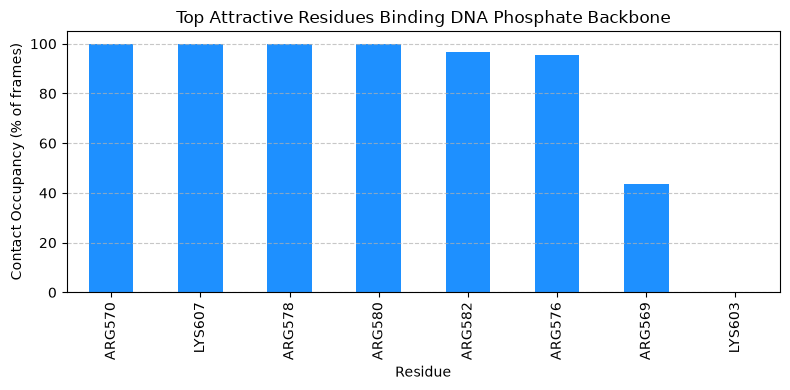

In [17]:
import pandas as pd
import numpy as np
import MDAnalysis as mda
import matplotlib.pyplot as plt

print("Identifying top attractive and repulsive residues across the trajectory...")

# Select DNA phosphate backbone and protein charge groups
dna_phosphates = u.select_atoms("nucleic and name P OP1 OP2")
pos_protein = u.select_atoms("protein and resname ARG LYS HIS")
neg_protein = u.select_atoms("protein and resname ASP GLU")

def rank_residue_contacts(universe, protein_atoms, dna_atoms, cutoff=4.0, stride=10):
    residue_contact_counts = {}
    total_frames = 0
    
    for ts in universe.trajectory[::stride]:
        total_frames += 1
        # Compute distance array between protein atoms and DNA phosphates
        dist_matrix = mda.lib.distances.distance_array(
            protein_atoms.positions, dna_atoms.positions, box=universe.dimensions
        )
        
        # Get atom indices within distance cutoff
        prot_indices, _ = np.where(dist_matrix <= cutoff)
        
        # Count unique residues interacting per frame
        frame_residues = set()
        for idx in prot_indices:
            atom = protein_atoms.atoms[idx]
            res_id = f"{atom.resname}{atom.resid}"
            frame_residues.add(res_id)
            
        for res in frame_residues:
            residue_contact_counts[res] = residue_contact_counts.get(res, 0) + 1

    # Convert to percentage occupancy across the analyzed trajectory
    occupancy = {res: (count / total_frames) * 100 for res, count in residue_contact_counts.items()}
    return pd.Series(occupancy).sort_values(ascending=False)

# Run ranking calculation
top_attractive = rank_residue_contacts(u, pos_protein, dna_phosphates)
top_repulsive = rank_residue_contacts(u, neg_protein, dna_phosphates)

# Display top results
print("\n=== TOP ATTRACTIVE PROTEIN RESIDUES (Contact Occupancy % to DNA Phosphate) ===")
print(top_attractive.head(10).to_string() if not top_attractive.empty else "No attractive contacts found.")

print("\n=== TOP REPULSIVE PROTEIN RESIDUES (Contact Occupancy % near DNA Phosphate) ===")
print(top_repulsive.head(10).to_string() if not top_repulsive.empty else "No repulsive contacts (< 4 Å) detected.")

# Plot Top 5 Attractive Residues
if not top_attractive.empty:
    plt.figure(figsize=(8, 4))
    top_attractive.head(8).plot(kind='bar', color='dodgerblue')
    plt.title('Top Attractive Residues Binding DNA Phosphate Backbone')
    plt.xlabel('Residue')
    plt.ylabel('Contact Occupancy (% of frames)')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.savefig("Top_Attractive_Residues.png", dpi=300)
    plt.show()

# Advanced Analysis: DNA Helical Dynamics, Allosteric Correlation, and Ion Density

This section expands our analysis into three advanced structural biophysics methods:
1. **DNA Groove Dimensions:** Measures inter-phosphate distances across complementary strands to track major/minor groove width fluctuations induced by TCF4 binding.
2. **Dynamic Cross-Correlation Matrix (DCCM) & Network Mapping:** Computes atomic motion correlations ($C_\alpha$ and $P$ atoms) to identify allosteric communication channels and dynamic bottleneck residues.
3. **3D Spatial Distribution Functions (SDF):** Calculates 3D volumetric ion probability density ($\text{K}^+$ counterions) surrounding the polyanionic DNA backbone.

Calculating DNA Groove Widths (Inter-Phosphate Distances)...
Strand 1 Phosphates: 12, Strand 2 Phosphates: 11


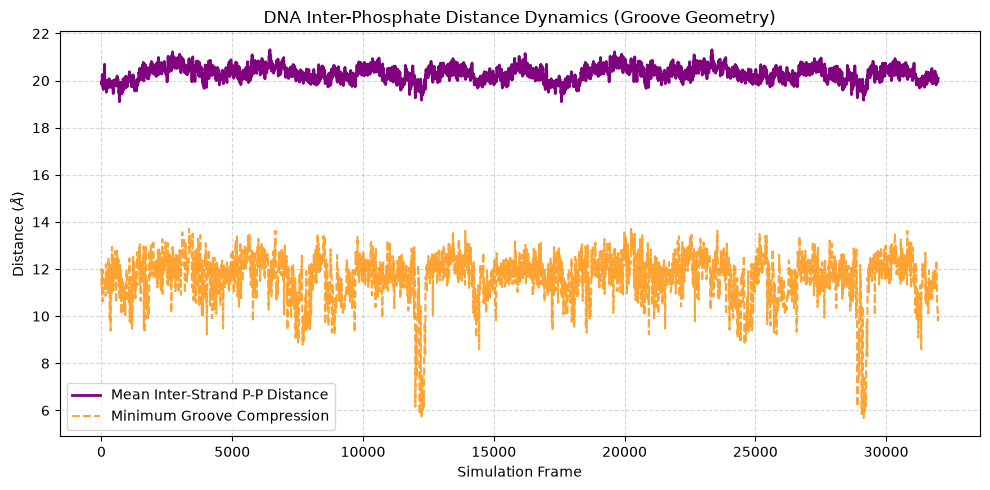

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import MDAnalysis as mda

print("Calculating DNA Groove Widths (Inter-Phosphate Distances)...")

# 1. Select phosphate atoms from the two complementary DNA strands
dna_p_strand1 = u.select_atoms("nucleic and name P and segid DNAA") # Adjust segid/chain if needed
dna_p_strand2 = u.select_atoms("nucleic and name P and segid DNAB")

# Fallback selection if segids are not explicitly DNAA/DNAB
if len(dna_p_strand1) == 0 or len(dna_p_strand2) == 0:
    all_p = u.select_atoms("nucleic and name P")
    n_p = len(all_p) // 2
    dna_p_strand1 = all_p[:n_p]
    dna_p_strand2 = all_p[n_p:]

print(f"Strand 1 Phosphates: {len(dna_p_strand1)}, Strand 2 Phosphates: {len(dna_p_strand2)}")

# 2. Track inter-phosphate distance array over trajectory
groove_distances = []

for ts in u.trajectory[::10]:
    # Calculate pairwise distance matrix between Strand 1 and Strand 2 phosphates
    dist_matrix = mda.lib.distances.distance_array(
        dna_p_strand1.positions, dna_p_strand2.positions, box=u.dimensions
    )
    # Average across inter-strand phosphate pairs to compute mean groove width
    mean_dist = np.mean(dist_matrix)
    min_dist = np.min(dist_matrix)
    groove_distances.append([ts.frame, mean_dist, min_dist])

groove_data = np.array(groove_distances)

# 3. Plot DNA Groove Width Profile
plt.figure(figsize=(10, 5))
plt.plot(groove_data[:, 0], groove_data[:, 1], color='purple', label='Mean Inter-Strand P-P Distance', linewidth=2)
plt.plot(groove_data[:, 0], groove_data[:, 2], color='darkorange', linestyle='--', label='Minimum Groove Compression', alpha=0.8)
plt.title('DNA Inter-Phosphate Distance Dynamics (Groove Geometry)')
plt.xlabel('Simulation Frame')
plt.ylabel('Distance ($\AA$)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("DNA_Groove_Dimensions.png", dpi=300)
plt.show()

Computing Dynamic Cross-Correlation Matrix (DCCM)...


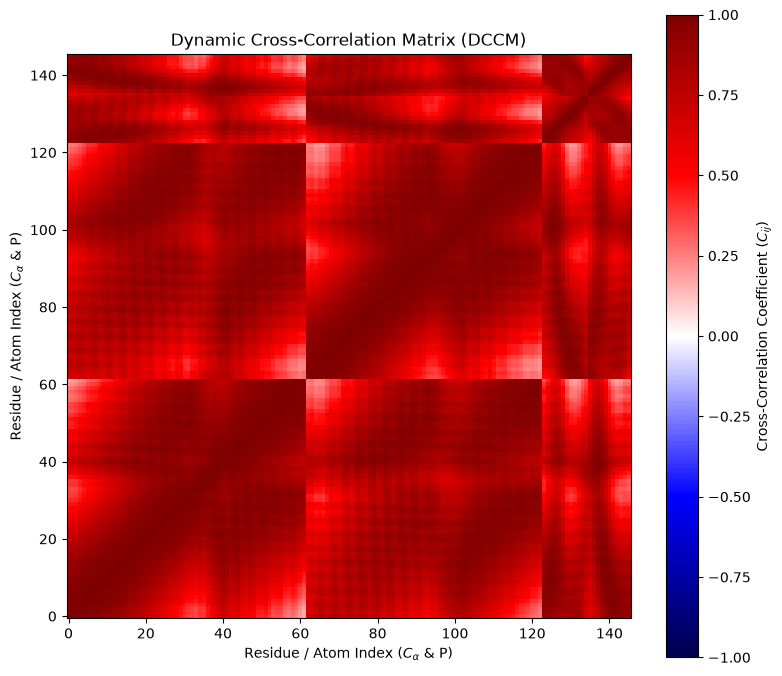

Building Allosteric Interaction Network...

=== TOP 5 ALLOSTERIC BOTTLENECK NODES ===
Atom Index 103 (LEU608): Betweenness Centrality = 0.1052
Atom Index 79 (ILE584): Betweenness Centrality = 0.0994
Atom Index 10 (GLU577): Betweenness Centrality = 0.0954
Atom Index 13 (ARG580): Betweenness Centrality = 0.0949
Atom Index 76 (VAL581): Betweenness Centrality = 0.0926


In [19]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

print("Computing Dynamic Cross-Correlation Matrix (DCCM)...")

# 1. Select Alpha Carbons (Protein) and Phosphates (DNA)
ca_p_atoms = u.select_atoms("(protein and name CA) or (nucleic and name P)")
n_atoms = len(ca_p_atoms)

# Extract atomic positions across trajectory
pos_list = []
for ts in u.trajectory[::10]:
    pos_list.append(ca_p_atoms.positions.copy())

pos_array = np.array(pos_list) # Shape: (n_frames, n_atoms, 3)

# 2. Compute Mean Positions & Deviations
mean_pos = np.mean(pos_array, axis=0)
deviations = pos_array - mean_pos # Shape: (n_frames, n_atoms, 3)

# 3. Compute Pairwise Correlation Matrix (C_ij)
dccm = np.zeros((n_atoms, n_atoms))

# Calculate dot products of atomic displacements over time
for i in range(n_atoms):
    dev_i = deviations[:, i, :] # (n_frames, 3)
    norm_i = np.sqrt(np.sum(np.mean(dev_i**2, axis=0)))
    for j in range(i, n_atoms):
        dev_j = deviations[:, j, :] # (n_frames, 3)
        norm_j = np.sqrt(np.sum(np.mean(dev_j**2, axis=0)))
        
        # Dot product averaged over frames
        dot_product = np.mean(np.sum(dev_i * dev_j, axis=1))
        
        corr = dot_product / (norm_i * norm_j + 1e-8)
        dccm[i, j] = corr
        dccm[j, i] = corr

# 4. Plot DCCM Heatmap
plt.figure(figsize=(8, 7))
plt.imshow(dccm, cmap='seismic', vmin=-1.0, vmax=1.0, origin='lower')
plt.colorbar(label='Cross-Correlation Coefficient ($C_{ij}$)')
plt.title('Dynamic Cross-Correlation Matrix (DCCM)')
plt.xlabel('Residue / Atom Index ($C_\\alpha$ & P)')
plt.ylabel('Residue / Atom Index ($C_\\alpha$ & P)')
plt.tight_layout()
plt.savefig("DCCM_Heatmap.png", dpi=300)
plt.show()

# 5. Graph Network Analysis: Identify Allosteric Bottlenecks
print("Building Allosteric Interaction Network...")
G = nx.Graph()

# Add edges where correlation magnitude is strong (|C_ij| > 0.4)
for i in range(n_atoms):
    for j in range(i + 1, n_atoms):
        val = abs(dccm[i, j])
        if val > 0.4:
            # Weight conversion: higher correlation = shorter path length
            weight = -np.log(val + 1e-5)
            G.add_edge(i, j, weight=weight)

# Calculate Betweenness Centrality (Bottleneck Nodes)
centrality = nx.betweenness_centrality(G, weight='weight')
top_hubs = sorted(centrality.items(), key=lambda x: x[1], reverse=True)[:5]

print("\n=== TOP 5 ALLOSTERIC BOTTLENECK NODES ===")
for node_idx, score in top_hubs:
    atom = ca_p_atoms.atoms[node_idx]
    print(f"Atom Index {node_idx} ({atom.resname}{atom.resid}): Betweenness Centrality = {score:.4f}")

Generating 3D Ion Density Map (Spatial Distribution Function)...
Selected 110 counterions for spatial distribution analysis.
Exported 3D Ion Density Grid to 'Ion_Density_3D.dx'


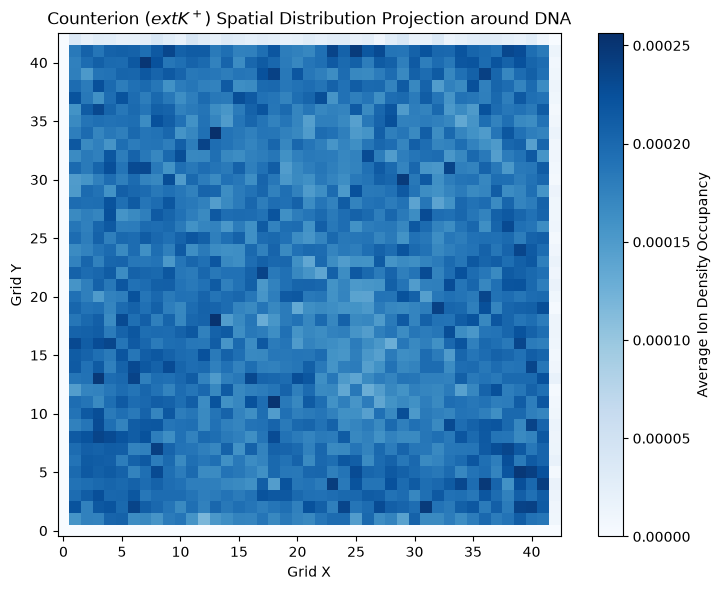

In [21]:
from MDAnalysis.analysis import density
import matplotlib.pyplot as plt
import numpy as np
import os

print("Generating 3D Ion Density Map (Spatial Distribution Function)...")

# 1. Select potassium ions (K+) or chlorine ions (Cl-)
ions = u.select_atoms("resname POT K K+ CLA CL")

if len(ions) == 0:
    print("No explicitly named counterions found. Checking all ions...")
    ions = u.select_atoms("resname ION or name K* Na* Cl*")

print(f"Selected {len(ions)} counterions for spatial distribution analysis.")

# 2. Perform 3D Grid Density Analysis
grid_density = density.DensityAnalysis(
    ions,
    delta=2.0 # Grid resolution in Angstroms
)
grid_density.run(step=10)

# FIX: Access grid via results.density and omit type="dx"
grid_density.results.density.export("Ion_Density_3D.dx")
print("Exported 3D Ion Density Grid to 'Ion_Density_3D.dx'")

# 3. 2D Maximum Intensity Projection Plot
# FIX: Access grid array via results.density.grid
density_matrix = grid_density.results.density.grid

# Average density along Z-axis to visualize XY plane condensation
proj_2d = np.mean(density_matrix, axis=2)

plt.figure(figsize=(8, 6))
plt.imshow(proj_2d, cmap='Blues', origin='lower')
plt.colorbar(label='Average Ion Density Occupancy')
plt.title('Counterion ($\text{K}^+$) Spatial Distribution Projection around DNA')
plt.xlabel('Grid X')
plt.ylabel('Grid Y')
plt.tight_layout()
plt.savefig("Ion_Spatial_Distribution_Projection.png", dpi=300)
plt.show()